In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/batooljuaitem/titanic/gender_submission.csv
/kaggle/input/datasets/batooljuaitem/titanic/test.csv
/kaggle/input/datasets/batooljuaitem/titanic/train.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/batooljuaitem/titanic/gender_submission.csv
/kaggle/input/datasets/batooljuaitem/titanic/test.csv
/kaggle/input/datasets/batooljuaitem/titanic/train.csv


In [4]:
# Load Titanic training dataset

df = pd.read_csv('/kaggle/input/datasets/batooljuaitem/titanic/train.csv')

# Display first 5 rows

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (891, 12)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [9]:
# Check data types of each column

print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [10]:
# Drop unnecessary columns

df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

# Display remaining columns

print("Remaining Columns:")
print(df.columns)

Remaining Columns:
Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='object')


In [11]:
# Handle missing values

df['Age'] = df['Age'].fillna(df['Age'].median())

df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Check missing values again

print("Missing Values After Handling:")
print(df.isnull().sum())

Missing Values After Handling:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [12]:
# Convert categorical columns into numerical values

df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

df = pd.get_dummies(df, columns=['Embarked'], dtype=int)

# Display the updated dataset

df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


In [13]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

Dataset Shape:
(891, 10)

First 5 Rows:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


In [14]:
# Separate Features and Target

X = df.drop('Survived', axis=1).values
y = df['Survived'].values

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (891, 9)
Target Shape: (891,)


In [15]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Shape: (712, 9)
Testing Shape: (179, 9)
Training Target Shape: (712,)
Testing Target Shape: (179,)


In [16]:
# Apply Standardization

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print("Training Mean:", np.mean(X_train, axis=0))
print("Training Standard Deviation:", np.std(X_train, axis=0))

Training Mean: [-1.48445550e-16  2.78803198e-16  2.00779624e-16 -1.17259510e-16
 -8.57616100e-18  1.48576142e-15  1.50160783e-16  6.01266852e-16
  2.27969953e-16]
Training Standard Deviation: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [17]:
# Define Sigmoid Function

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Test Sigmoid Function

print(sigmoid(0))
print(sigmoid(2))
print(sigmoid(-2))

0.5
0.8807970779778823
0.11920292202211755


In [18]:
# Initialize weights and bias

n_features = X_train.shape[1]

weights = np.zeros(n_features)
bias = 0.0

print("Number of Features:", n_features)
print("Initial Weights:", weights)
print("Initial Bias:", bias)

Number of Features: 9
Initial Weights: [0. 0. 0. 0. 0. 0. 0. 0. 0.]
Initial Bias: 0.0


In [19]:
# Define prediction function

def predict_probability(X, weights, bias):
    z = np.dot(X, weights) + bias
    return sigmoid(z)

# Test prediction

probabilities = predict_probability(X_train[:5], weights, bias)

print("Predicted Probabilities:")
print(probabilities)

Predicted Probabilities:
[0.5 0.5 0.5 0.5 0.5]


In [20]:
# Define Binary Cross-Entropy Loss

def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

# Test Loss Function

initial_probabilities = predict_probability(X_train, weights, bias)

initial_loss = compute_loss(y_train, initial_probabilities)

print("Initial Loss:", initial_loss)

Initial Loss: 0.6931471805599453


In [21]:
# Compute Gradients

def compute_gradients(X, y, weights, bias):
    m = X.shape[0]

    y_pred = predict_probability(X, weights, bias)

    dw = np.dot(X.T, (y_pred - y)) / m
    db = np.sum(y_pred - y) / m

    return dw, db

# Test Gradients

dw, db = compute_gradients(X_train, y_train, weights, bias)

print("Weight Gradients:", dw)
print("Bias Gradient:", db)

Weight Gradients: [ 0.16920806 -0.26701845  0.03467957  0.01269755 -0.04092904 -0.1339534
 -0.08753393 -0.01531635  0.0871128 ]
Bias Gradient: 0.11657303370786516


In [22]:
# Gradient Descent Optimizer

def train_gd(X, y, learning_rate=0.01, epochs=1000):

    m, n = X.shape

    weights = np.zeros(n)
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        dw, db = compute_gradients(X, y, weights, bias)

        weights -= learning_rate * dw
        bias -= learning_rate * db

        y_pred = predict_probability(X, weights, bias)
        loss = compute_loss(y, y_pred)

        loss_history.append(loss)

        if (epoch + 1) % 100 == 0:
            print(f"Epoch {epoch + 1}, Loss: {loss:.4f}")

    return weights, bias, loss_history

In [23]:
gd_weights, gd_bias, gd_loss_history = train_gd(
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=1000
)

print("GD Training Completed!")
print("Final Loss:", gd_loss_history[-1])

Epoch 100, Loss: 0.5895
Epoch 200, Loss: 0.5377
Epoch 300, Loss: 0.5079
Epoch 400, Loss: 0.4891
Epoch 500, Loss: 0.4765
Epoch 600, Loss: 0.4676
Epoch 700, Loss: 0.4612
Epoch 800, Loss: 0.4563
Epoch 900, Loss: 0.4527
Epoch 1000, Loss: 0.4498
GD Training Completed!
Final Loss: 0.4498273620073057


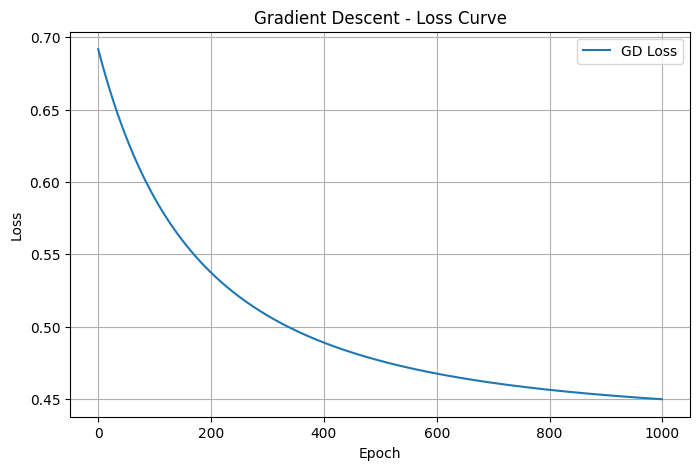

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(gd_loss_history, label='GD Loss')

plt.title('Gradient Descent - Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.show()

In [25]:
# Evaluate GD Model

y_prob_gd = predict_probability(X_test, gd_weights, gd_bias)

y_pred_gd = (y_prob_gd >= 0.5).astype(int)

gd_accuracy = accuracy_score(y_test, y_pred_gd)
gd_precision = precision_score(y_test, y_pred_gd)
gd_recall = recall_score(y_test, y_pred_gd)
gd_f1 = f1_score(y_test, y_pred_gd)

print("GD Results:")
print("Accuracy:", gd_accuracy)
print("Precision:", gd_precision)
print("Recall:", gd_recall)
print("F1 Score:", gd_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gd))

GD Results:
Accuracy: 0.7877094972067039
Precision: 0.7540983606557377
Recall: 0.6666666666666666
F1 Score: 0.7076923076923077

Confusion Matrix:
[[95 15]
 [23 46]]


In [26]:

import numpy as np
import matplotlib.pyplot as plt

# GD with Momentum
def train_gd_momentum(X, y, learning_rate=0.01,
                      epochs=1000, beta=0.9):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    v_w = np.zeros(n_features)
    v_b = 0.0

    losses = []

    for epoch in range(epochs):

        y_prob = 1 / (1 + np.exp(
            -np.clip(X @ weights + bias, -500, 500)
        ))

        dw = (X.T @ (y_prob - y)) / n_samples
        db = np.mean(y_prob - y)

        # Momentum update
        v_w = beta * v_w + dw
        v_b = beta * v_b + db

        weights -= learning_rate * v_w
        bias -= learning_rate * v_b

        # Calculate loss
        y_prob = 1 / (1 + np.exp(
            -np.clip(X @ weights + bias, -500, 500)
        ))

        epsilon = 1e-15

        loss = -np.mean(
            y * np.log(y_prob + epsilon) +
            (1 - y) * np.log(1 - y_prob + epsilon)
        )

        losses.append(loss)

        if (epoch + 1) % 100 == 0:
            print(f"Epoch {epoch+1}, Loss: {loss:.4f}")

    return weights, bias, losses


momentum_weights, momentum_bias, momentum_losses = train_gd_momentum(
    X_train, y_train,
    learning_rate=0.01,
    epochs=1000,
    beta=0.9
)


Epoch 100, Loss: 0.4481
Epoch 200, Loss: 0.4388
Epoch 300, Loss: 0.4371
Epoch 400, Loss: 0.4366
Epoch 500, Loss: 0.4364
Epoch 600, Loss: 0.4363
Epoch 700, Loss: 0.4363
Epoch 800, Loss: 0.4363
Epoch 900, Loss: 0.4363
Epoch 1000, Loss: 0.4363


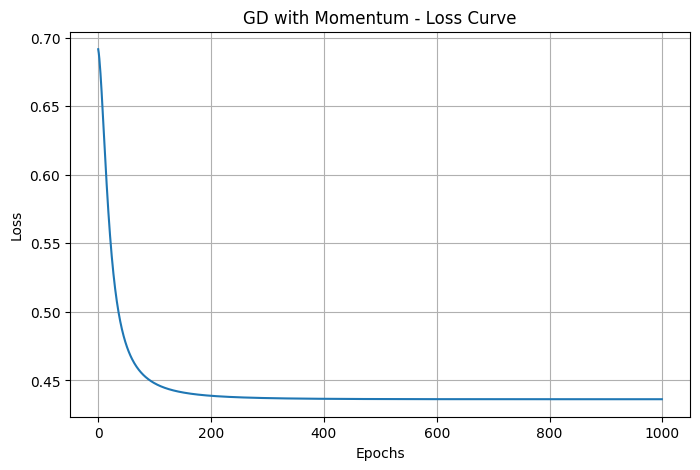

In [27]:

plt.figure(figsize=(8, 5))

plt.plot(momentum_losses)

plt.title("GD with Momentum - Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)

plt.show()


In [28]:

y_prob_momentum = predict_probability(
    X_test, momentum_weights, momentum_bias
)

y_pred_momentum = (y_prob_momentum >= 0.5).astype(int)

momentum_accuracy = accuracy_score(y_test, y_pred_momentum)
momentum_precision = precision_score(y_test, y_pred_momentum)
momentum_recall = recall_score(y_test, y_pred_momentum)
momentum_f1 = f1_score(y_test, y_pred_momentum)

print("GD with Momentum Results:")
print("Accuracy:", momentum_accuracy)
print("Precision:", momentum_precision)
print("Recall:", momentum_recall)
print("F1 Score:", momentum_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_momentum))


GD with Momentum Results:
Accuracy: 0.8044692737430168
Precision: 0.7931034482758621
Recall: 0.6666666666666666
F1 Score: 0.7244094488188977

Confusion Matrix:
[[98 12]
 [23 46]]


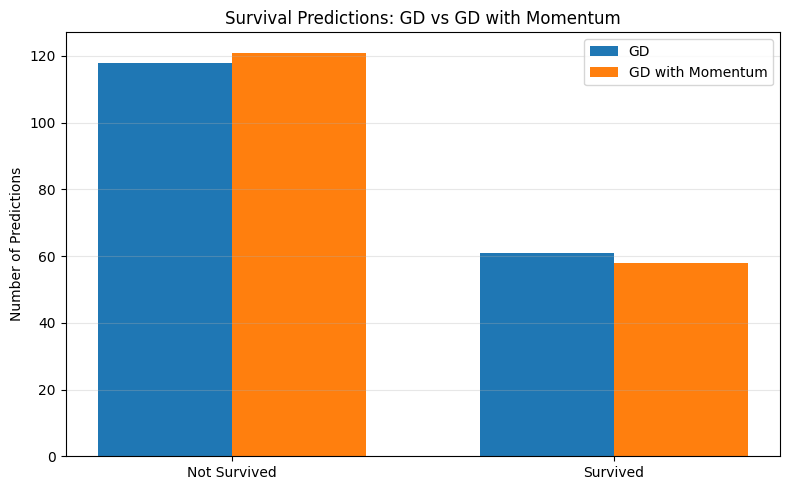

In [29]:

import numpy as np
import matplotlib.pyplot as plt

gd_counts = [
    np.sum(y_pred_gd == 0),
    np.sum(y_pred_gd == 1)
]

momentum_counts = [
    np.sum(y_pred_momentum == 0),
    np.sum(y_pred_momentum == 1)
]

labels = ['Not Survived', 'Survived']

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, gd_counts, width, label='GD')
plt.bar(x + width/2, momentum_counts, width,
        label='GD with Momentum')

plt.xticks(x, labels)
plt.ylabel('Number of Predictions')
plt.title('Survival Predictions: GD vs GD with Momentum')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


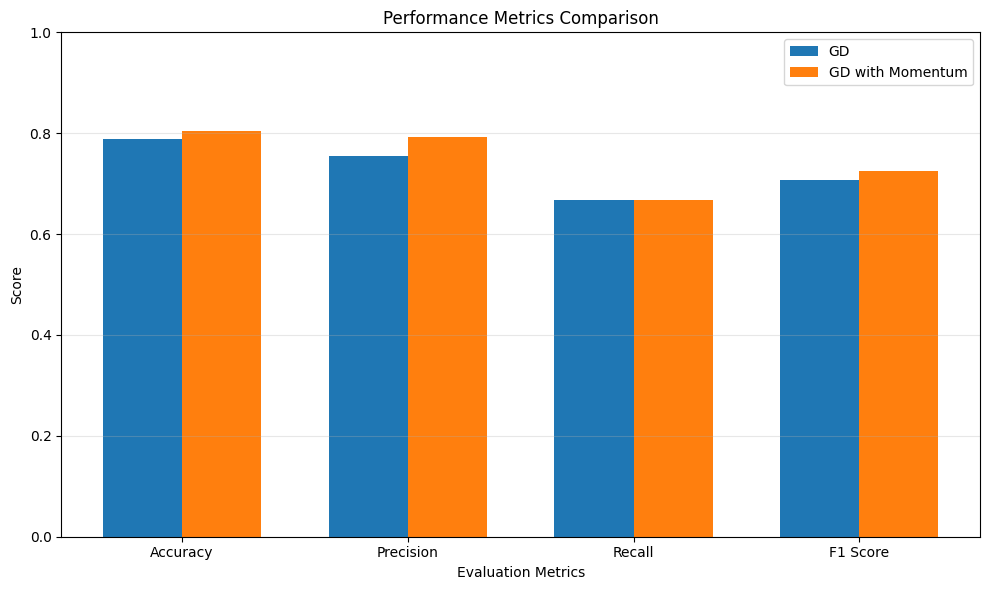

In [30]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

gd_scores = [
    gd_accuracy,
    gd_precision,
    gd_recall,
    gd_f1
]

momentum_scores = [
    momentum_accuracy,
    momentum_precision,
    momentum_recall,
    momentum_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, gd_scores, width, label='GD')
plt.bar(x + width/2, momentum_scores, width,
        label='GD with Momentum')

plt.title('Performance Metrics Comparison')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


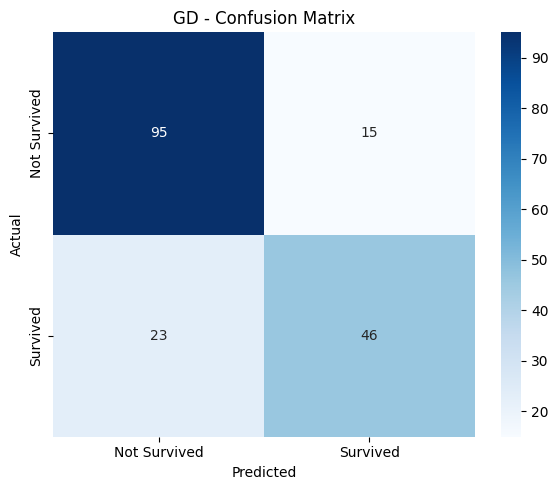

In [31]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_gd),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title('GD - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


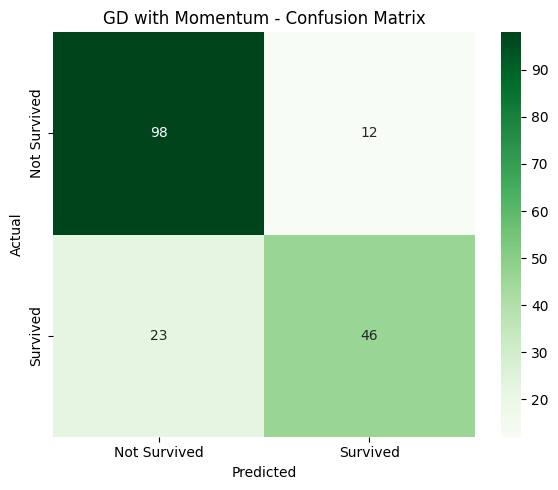

In [32]:

plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_momentum),
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title('GD with Momentum - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()
